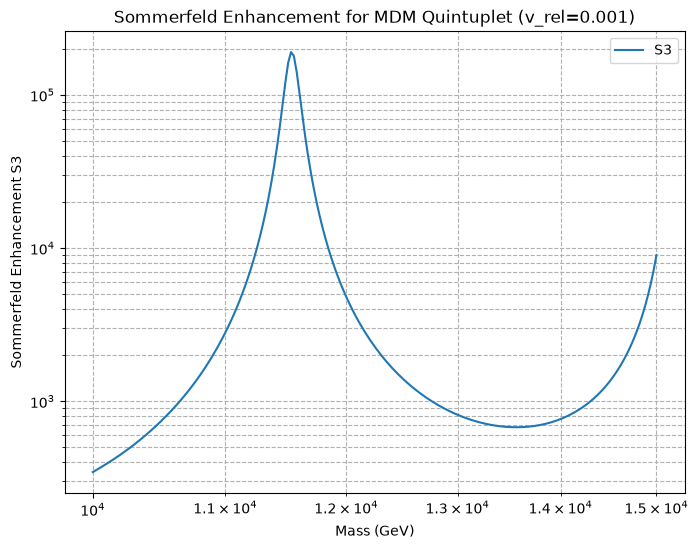

In [2]:
import numpy as np
from sommerfeld_mdm.sommerfeld import sommerfeld
from sommerfeld_mdm.mdm import mdm_quintupletQ0S0
import matplotlib.pyplot as plt

v_rel = 0.001
Mw = 80.379

masses = np.logspace(4, np.log10(15000), 200)
S3_vals = np.zeros(len(masses))

for M in masses:
    p = M * v_rel / 2
    x_inf = max(100.0, 10.0 * p / Mw)
    V_inf, V_eff, Gamma = mdm_quintupletQ0S0(M)
    T = sommerfeld(
        M=M,
        v_rel=v_rel/2,
        V_inf=V_inf,
        V_eff=V_eff,
        x_inf=x_inf
    )
    T_conj = T.conj().T
    S3_vals[np.where(masses == M)] = (T_conj @ Gamma @ T)[2, 2].real / Gamma[2, 2]

S3_max = np.max(S3_vals)
mass_max = masses[np.argmax(S3_vals)]

plt.figure(figsize=(8, 6))
plt.loglog(masses, S3_vals, label="S3")
plt.xlabel("Mass (GeV)")
plt.ylabel("Sommerfeld Enhancement S3")
plt.title(f"Sommerfeld Enhancement for MDM Quintuplet (v_rel={v_rel})")
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()


In [3]:
mass_max

np.float64(11532.982921660527)